# 가우시안 나이브 베이즈 (Gaussian Naive Bayes) — Setosa vs Versicolor
꽃받침 길이(**sepal.length**) 하나만 보고, 길이가 **7.2 cm**인 꽃이 Setosa인지 Versicolor인지 맞혀 본다.

- 사전확률(prior)은 두 품종 모두 똑같이 **1/2**로 가정
- 각 품종의 sepal.length가 **정규분포(normal distribution)**를 따른다고 가정

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/iris.csv")

FEATURE = "sepal.length"
CLASSES = ["Setosa", "Versicolor"]
CLASS_COLORS = {"Setosa": "tab:blue", "Versicolor": "tab:orange"}
X_QUERY = 7.2

BINS = np.round(np.arange(4.25, 8.1 + 1e-9, 0.2), 2)   # width 0.2, edges from 4.25
X_GRID = np.linspace(4.1, 8.1, 500)
X_LIM = (4.1, 8.1)


def normal_pdf(x, mu, sigma):
    """Gaussian pdf implemented from its formula (no scipy)."""
    return np.exp(-(x - mu) ** 2 / (2 * sigma ** 2)) / (sigma * np.sqrt(2 * np.pi))


def normal_label(name, mu, sigma):
    return f"{name}  N({mu:.3f}, {sigma:.3f}²)"

## 1. 품종별 통계 (n · 평균 · 표준편차)
**확률분포 구하기 = 평균·표준편차 구하기** (정규분포는 평균 μ와 표준편차 σ만 알면 모양이 정해진다)

In [2]:
samples = {
    "Setosa": df.loc[df["variety"] == "Setosa", FEATURE],
    "Versicolor": df.loc[df["variety"] == "Versicolor", FEATURE],
    "All (150)": df[FEATURE],
}

stats = pd.DataFrame(
    {name: {"n": len(v), "mean": v.mean(), "std (ddof=1)": v.std(ddof=1)}
     for name, v in samples.items()}
).T
stats["n"] = stats["n"].astype(int)

params = {name: (row["mean"], row["std (ddof=1)"]) for name, row in stats.iterrows()}
stats.round(3)

,n,mean,std (ddof=1)
Setosa,50,5.006,0.352
Versicolor,50,5.936,0.516
All (150),150,5.843,0.828


## 2. Setosa 분포 보기
막대는 실제 데이터(히스토그램), 실선은 평균·표준편차로 그린 정규분포 곡선이다. 빨간 점선은 품종 구분 없이 150개 전체로 그린 곡선이다.

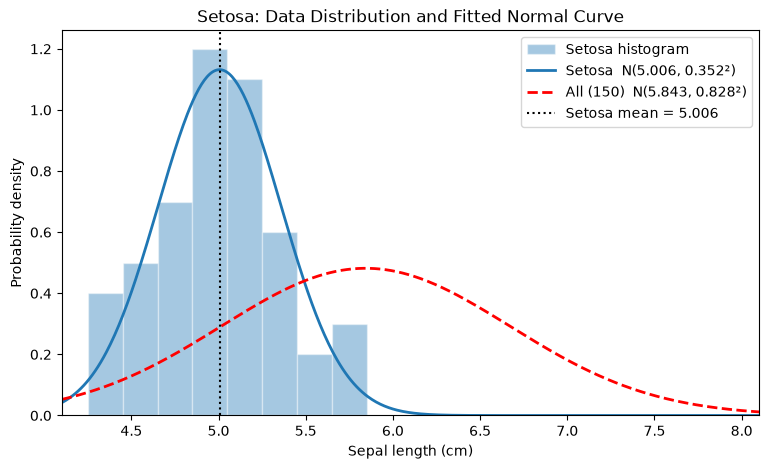

In [3]:
mu_s, sd_s = params["Setosa"]
mu_all, sd_all = params["All (150)"]

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(samples["Setosa"], bins=BINS, density=True, color="tab:blue", alpha=0.4,
        edgecolor="white", label="Setosa histogram")
ax.plot(X_GRID, normal_pdf(X_GRID, mu_s, sd_s), color="tab:blue", linewidth=2,
        label=normal_label("Setosa", mu_s, sd_s))
ax.plot(X_GRID, normal_pdf(X_GRID, mu_all, sd_all), color="red", linestyle="--", linewidth=2,
        label=normal_label("All (150)", mu_all, sd_all))
ax.axvline(mu_s, color="black", linestyle=":", linewidth=1.5, label=f"Setosa mean = {mu_s:.3f}")
ax.set_xlim(X_LIM)
ax.set_title("Setosa: Data Distribution and Fitted Normal Curve")
ax.set_xlabel("Sepal length (cm)")
ax.set_ylabel("Probability density")
ax.legend()
plt.show()

## 3. Versicolor 분포 보기
Versicolor 곡선을 Setosa 곡선, 전체 곡선과 한 그래프에서 비교한다.

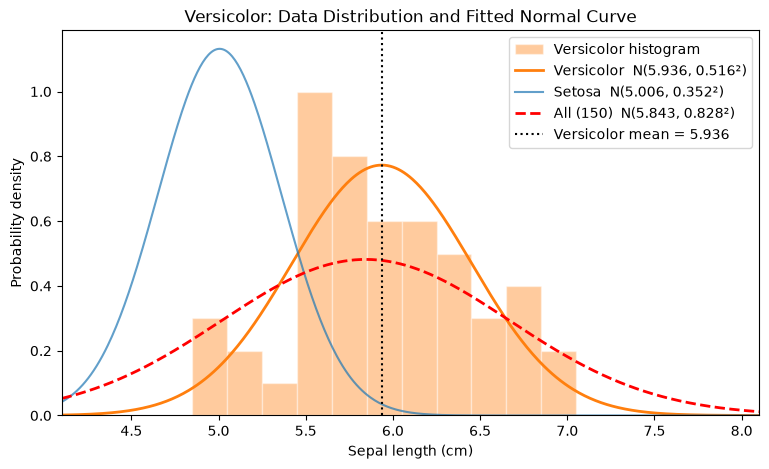

In [4]:
mu_v, sd_v = params["Versicolor"]

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(samples["Versicolor"], bins=BINS, density=True, color="tab:orange", alpha=0.4,
        edgecolor="white", label="Versicolor histogram")
ax.plot(X_GRID, normal_pdf(X_GRID, mu_v, sd_v), color="tab:orange", linewidth=2,
        label=normal_label("Versicolor", mu_v, sd_v))
ax.plot(X_GRID, normal_pdf(X_GRID, mu_s, sd_s), color="tab:blue", linewidth=1.5, alpha=0.7,
        label=normal_label("Setosa", mu_s, sd_s))
ax.plot(X_GRID, normal_pdf(X_GRID, mu_all, sd_all), color="red", linestyle="--", linewidth=2,
        label=normal_label("All (150)", mu_all, sd_all))
ax.axvline(mu_v, color="black", linestyle=":", linewidth=1.5, label=f"Versicolor mean = {mu_v:.3f}")
ax.set_xlim(X_LIM)
ax.set_title("Versicolor: Data Distribution and Fitted Normal Curve")
ax.set_xlabel("Sepal length (cm)")
ax.set_ylabel("Probability density")
ax.legend()
plt.show()

## 4. 두 품종 비교: 결정경계와 x = 7.2
- **결정경계(decision boundary)**: 두 곡선 높이가 같아지는 x. 사전확률이 같으면 이 선을 기준으로 왼쪽은 Setosa, 오른쪽은 Versicolor로 판정한다.
- 두 품종의 σ가 달라서, 경계를 구하면 2차방정식이 나온다. 근 두 개 중 **두 평균 사이에 있는 근**을 경계로 쓴다.
- x = 7.2에서 곡선 높이가 **우도(likelihood) f(x|품종)**이고, 이것으로 **사후확률(posterior)**을 계산한다.

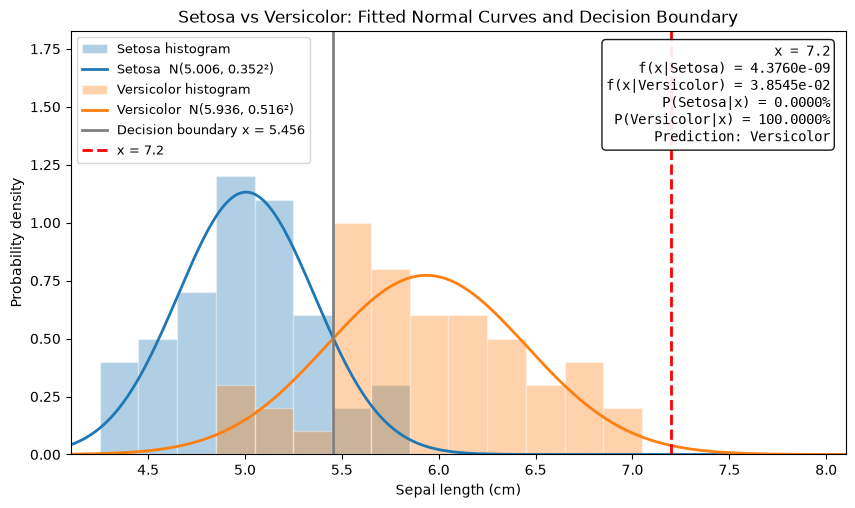

Decision boundary: x = 5.4558 cm


In [5]:
def decision_boundary(mu1, sd1, mu2, sd2):
    """x between the two means where normal_pdf(x, mu1, sd1) == normal_pdf(x, mu2, sd2)."""
    a = 1 / (2 * sd2 ** 2) - 1 / (2 * sd1 ** 2)
    b = mu1 / sd1 ** 2 - mu2 / sd2 ** 2
    c = mu2 ** 2 / (2 * sd2 ** 2) - mu1 ** 2 / (2 * sd1 ** 2) + np.log(sd2 / sd1)
    roots = np.roots([a, b, c])
    roots = roots[np.isreal(roots)].real
    return roots[(roots > min(mu1, mu2)) & (roots < max(mu1, mu2))][0]


boundary = decision_boundary(mu_s, sd_s, mu_v, sd_v)

likelihoods = {c: normal_pdf(X_QUERY, *params[c]) for c in CLASSES}
evidence = sum(0.5 * likelihoods[c] for c in CLASSES)
posteriors = {c: 0.5 * likelihoods[c] / evidence for c in CLASSES}
prediction = max(posteriors, key=posteriors.get)

fig, ax = plt.subplots(figsize=(10, 5.5))
for c in CLASSES:
    mu, sd = params[c]
    color = CLASS_COLORS[c]
    ax.hist(samples[c], bins=BINS, density=True, color=color, alpha=0.35,
            edgecolor="white", label=f"{c} histogram")
    ax.plot(X_GRID, normal_pdf(X_GRID, mu, sd), color=color, linewidth=2,
            label=normal_label(c, mu, sd))
ax.axvline(boundary, color="gray", linewidth=2, label=f"Decision boundary x = {boundary:.3f}")
ax.axvline(X_QUERY, color="red", linestyle="--", linewidth=2, label=f"x = {X_QUERY}")

info = (f"x = {X_QUERY}\n"
        f"f(x|Setosa) = {likelihoods['Setosa']:.4e}\n"
        f"f(x|Versicolor) = {likelihoods['Versicolor']:.4e}\n"
        f"P(Setosa|x) = {posteriors['Setosa']:.4%}\n"
        f"P(Versicolor|x) = {posteriors['Versicolor']:.4%}\n"
        f"Prediction: {prediction}")
ax.text(0.98, 0.97, info, transform=ax.transAxes, ha="right", va="top", family="monospace",
        bbox=dict(boxstyle="round", facecolor="white", alpha=0.9))
ax.set_xlim(X_LIM)
ax.set_ylim(0, ax.get_ylim()[1] * 1.45)   # headroom for legend and text box
ax.set_title("Setosa vs Versicolor: Fitted Normal Curves and Decision Boundary")
ax.set_xlabel("Sepal length (cm)")
ax.set_ylabel("Probability density")
ax.legend(loc="upper left", fontsize=9)
plt.show()

print(f"Decision boundary: x = {boundary:.4f} cm")

## 5. classify(x) 함수로 판별하기
x를 넣으면 품종별 우도 → 사후확률 → 최종 판정 순서로 출력한다. x = 7.2와 x = 5.0을 넣어 본다.

In [6]:
def classify(x, priors=None):
    """Gaussian Naive Bayes on sepal.length: print likelihoods, posteriors and the prediction."""
    priors = priors or {c: 1 / len(CLASSES) for c in CLASSES}
    likelihoods = {c: normal_pdf(x, *params[c]) for c in CLASSES}
    joint = {c: priors[c] * likelihoods[c] for c in CLASSES}
    evidence = sum(joint.values())
    posteriors = {c: joint[c] / evidence for c in CLASSES}
    prediction = max(posteriors, key=posteriors.get)

    print(f"x = {x} cm")
    for c in CLASSES:
        print(f"  {c:<11} f(x|c) = {likelihoods[c]:.4e}   P(c|x) = {posteriors[c]:.4%}")
    print(f"  -> Prediction: {prediction}\n")
    return prediction


for x in [7.2, 5.0]:
    classify(x)

x = 7.2 cm
  Setosa      f(x|c) = 4.3760e-09   P(c|x) = 0.0000%
  Versicolor  f(x|c) = 3.8545e-02   P(c|x) = 100.0000%
  -> Prediction: Versicolor

x = 5.0 cm
  Setosa      f(x|c) = 1.1316e+00   P(c|x) = 88.3438%
  Versicolor  f(x|c) = 1.4931e-01   P(c|x) = 11.6562%
  -> Prediction: Setosa

